# Pricing

In [1]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
from dotenv import load_dotenv
import os


load_dotenv()

USER_NAME = os.getenv("USER_NAME")
PASSWORD = os.getenv("PASSWORD")
HOST = os.getenv("HOST")
PORT = os.getenv("PORT")
DB_NAME = os.getenv("DB_NAME")

DATABASE_URL = rf"postgresql+psycopg2://{USER_NAME}:{PASSWORD}@{HOST}:{PORT}/{DB_NAME}"
engine = create_engine(DATABASE_URL)


In [2]:
sql = 'SELECT * FROM warehouse.vw_warehouse_sales; '
df = pd.read_sql(sql, con=engine)

In [3]:
pr_oi = 'Rice - Basmati'
r_basmati = df[df['product'] ==pr_oi].copy()
r_basmati

,sales_key,week,start_date,product,sales_units,cost_of_goods_sold_cogs,inventory_level,demand_forecast,price_per_unit,gross_profit,operating_profit,revenue,inventory_turnover_ratio,gross_profit_margin,revenue_growth,modified_row,run_id
0,1,1,2020-01-01,Rice - Basmati,1153.0,21.84,2915.0,1242.0,29.29,8589.85,5362.48,33771.37,0.28,0.2544,0.0000,False,20261002135808273756
1,2,2,2020-01-08,Rice - Basmati,1108.0,21.69,3307.0,1149.0,27.30,6215.88,3593.65,30248.40,0.38,0.2055,-0.1043,False,20261002135808273756
2,3,3,2020-01-15,Rice - Basmati,1527.0,22.38,3280.0,1639.0,27.48,7787.70,2713.53,41961.96,0.46,0.1856,0.3872,False,20261002135808273756
3,4,4,2020-01-22,Rice - Basmati,1299.0,21.41,1981.0,1093.0,26.56,6689.85,2756.27,34501.44,0.40,0.1939,-0.1778,False,20261002135808273756
4,5,5,2020-01-29,Rice - Basmati,1346.0,21.69,3135.0,1424.0,26.27,6164.68,1804.61,35359.42,0.68,0.1743,0.0249,False,20261002135808273756
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255,256,256,2024-11-20,Rice - Basmati,1109.0,21.61,14068.0,1392.0,28.01,7097.60,4623.34,31063.09,0.09,0.2285,-0.0343,False,20261002135808273756
256,257,257,2024-11-27,Rice - Basmati,1175.0,21.90,12893.0,1058.0,27.88,7026.50,3682.09,32759.00,0.08,0.2145,0.0546,False,20261002135808273756
257,258,258,2024-12-04,Rice - Basmati,1276.0,22.10,11617.0,1212.0,28.24,7834.64,4488.11,36034.24,0.10,0.2174,0.1000,False,20261002135808273756
258,259,259,2024-12-11,Rice - Basmati,1191.0,21.80,12926.0,1069.0,26.88,6050.28,2677.29,32014.08,0.10,0.1890,-0.1116,False,20261002135808273756


In [4]:
r_basmati.value_counts(['price_per_unit'])

price_per_unit
28.97             4
29.01             3
27.14             3
27.39             3
27.51             3
                 ..
25.99             1
29.42             1
28.69             1
29.24             1
27.70             1
Name: count, Length: 187, dtype: int64

In [5]:
r_basmati.value_counts(['cost_of_goods_sold_cogs'])

cost_of_goods_sold_cogs
21.83                      6
21.81                      5
22.21                      5
21.69                      4
22.24                      4
                          ..
21.87                      1
20.86                      1
21.98                      1
21.29                      1
22.10                      1
Name: count, Length: 137, dtype: int64

In [6]:
r_basmati['price_margin_percent']=r_basmati['price_per_unit']/r_basmati['cost_of_goods_sold_cogs']
r_basmati.value_counts(['price_margin_percent'])

price_margin_percent
1.210526                2
1.341117                1
1.258645                1
1.227882                1
1.240542                1
                       ..
1.296159                1
1.273059                1
1.277828                1
1.233028                1
1.325827                1
Name: count, Length: 259, dtype: int64

In [7]:
r_basmati.head()

,sales_key,week,start_date,product,sales_units,cost_of_goods_sold_cogs,inventory_level,demand_forecast,price_per_unit,gross_profit,operating_profit,revenue,inventory_turnover_ratio,gross_profit_margin,revenue_growth,modified_row,run_id,price_margin_percent
0,1,1,2020-01-01,Rice - Basmati,1153.0,21.84,2915.0,1242.0,29.29,8589.85,5362.48,33771.37,0.28,0.2544,0.0000,False,20261002135808273756,1.341117
1,2,2,2020-01-08,Rice - Basmati,1108.0,21.69,3307.0,1149.0,27.30,6215.88,3593.65,30248.40,0.38,0.2055,-0.1043,False,20261002135808273756,1.258645
2,3,3,2020-01-15,Rice - Basmati,1527.0,22.38,3280.0,1639.0,27.48,7787.70,2713.53,41961.96,0.46,0.1856,0.3872,False,20261002135808273756,1.227882
3,4,4,2020-01-22,Rice - Basmati,1299.0,21.41,1981.0,1093.0,26.56,6689.85,2756.27,34501.44,0.40,0.1939,-0.1778,False,20261002135808273756,1.240542
4,5,5,2020-01-29,Rice - Basmati,1346.0,21.69,3135.0,1424.0,26.27,6164.68,1804.61,35359.42,0.68,0.1743,0.0249,False,20261002135808273756,1.211157


In [8]:
r_basmati.value_counts(['sales_units'])

sales_units
0.0            5
970.0          3
1149.0         3
947.0          3
1153.0         2
              ..
999.0          1
1148.0         1
1175.0         1
1191.0         1
1513.0         1
Name: count, Length: 223, dtype: int64

In [9]:
q1_sales = np.quantile(r_basmati['sales_units'], 0.25)
q2_sales = np.quantile(r_basmati['sales_units'], 0.5)
q3_sales = np.quantile(r_basmati['sales_units'], 0.75)

In [10]:
q1_sales, q2_sales, q3_sales

(np.float64(1011.25), np.float64(1201.0), np.float64(1413.25))

In [24]:
very_low_demand_basmati = r_basmati[r_basmati['sales_units']<=q1_sales].copy()
low_demand_basmati = r_basmati[(r_basmati['sales_units']>q1_sales)& (r_basmati['sales_units']<=q2_sales)].copy()
high_demand_basmati = r_basmati[(r_basmati['sales_units']>q2_sales)& (r_basmati['sales_units']<=q3_sales)].copy()
very_high_demand_basmati = r_basmati[(r_basmati['sales_units']>q3_sales)].copy()

In [12]:
print(very_low_demand_basmati.shape)
very_low_demand_basmati.head()

(65, 18)


,sales_key,week,start_date,product,sales_units,cost_of_goods_sold_cogs,inventory_level,demand_forecast,price_per_unit,gross_profit,operating_profit,revenue,inventory_turnover_ratio,gross_profit_margin,revenue_growth,modified_row,run_id,price_margin_percent
19,20,20,2020-05-13,Rice - Basmati,922.0,21.67,2500.0,1400.0,26.72,4656.10,1947.70,24635.84,1.00,0.1890,-0.4398,False,20261002135808273756,1.233041
28,29,29,2020-07-15,Rice - Basmati,897.0,21.48,6339.0,896.0,27.85,5713.89,3142.71,24981.45,0.19,0.2287,-0.3653,False,20261002135808273756,1.296555
29,30,30,2020-07-22,Rice - Basmati,900.0,21.85,5439.0,917.0,27.14,4761.00,1925.80,24426.00,0.14,0.1949,-0.0222,False,20261002135808273756,1.242105
30,31,31,2020-07-29,Rice - Basmati,990.0,22.18,6949.0,906.0,29.83,7573.50,4319.71,29531.70,0.18,0.2565,0.2090,False,20261002135808273756,1.344905
31,32,32,2020-08-05,Rice - Basmati,855.0,21.81,8594.0,705.0,27.39,4770.90,2538.14,23418.45,0.12,0.2037,-0.2070,False,20261002135808273756,1.255846


In [13]:
# very_low_demand_basmati.value_counts(['cost_of_goods_sold_cogs'])
# very_low_demand_basmati.value_counts(['price_per_unit'])
very_low_demand_basmati.value_counts(['price_margin_percent'])

price_margin_percent
1.233041                1
1.296555                1
1.242105                1
1.344905                1
1.255846                1
                       ..
1.339344                1
1.322247                1
1.227066                1
1.311414                1
1.275103                1
Name: count, Length: 65, dtype: int64

In [14]:
import matplotlib.pyplot as plt

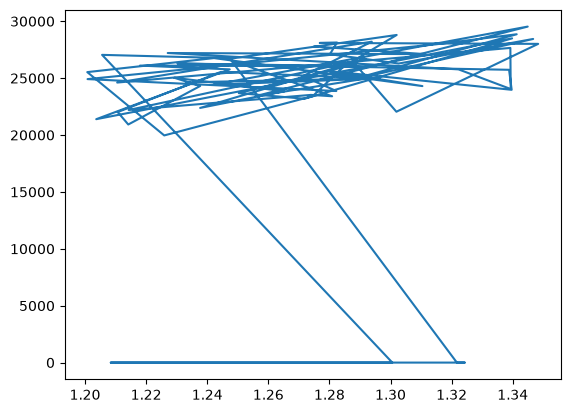

In [15]:
plt.plot(very_low_demand_basmati['price_margin_percent'], very_low_demand_basmati['revenue'])

In [44]:
df_oi.head(2)

,sales_key,week,start_date,product,sales_units,cost_of_goods_sold_cogs,inventory_level,demand_forecast,price_per_unit,gross_profit,operating_profit,revenue,inventory_turnover_ratio,gross_profit_margin,revenue_growth,modified_row,run_id,price_margin_percent
3,4,4,2020-01-22,Rice - Basmati,1299.0,21.41,1981.0,1093.0,26.56,6689.85,2756.27,34501.44,0.40,0.1939,-0.1778,False,20261002135808273756,1.240542
4,5,5,2020-01-29,Rice - Basmati,1346.0,21.69,3135.0,1424.0,26.27,6164.68,1804.61,35359.42,0.68,0.1743,0.0249,False,20261002135808273756,1.211157


In [57]:
# df_oi = high_demand_basmati
# df_oi = very_low_demand_basmati
df_oi = r_basmati

# metric = 'gross_profit_margin'
metric = 'gross_profit'
# metric = 'operating_profit'
print(df_oi['price_margin_percent'].min(), df_oi['price_margin_percent'].max())
q = df_oi[['price_margin_percent', 'sales_units', metric]].copy().sort_values([metric], ascending=False)
q

1.200729927007299 1.348987108655617


,price_margin_percent,sales_units,gross_profit
218,1.329581,1761.0,12890.52
222,1.318616,1746.0,12222.00
224,1.343042,1619.0,12012.98
227,1.347766,1529.0,11543.95
167,1.297685,1795.0,11541.85
...,...,...,...
69,1.300589,0.0,0.00
66,1.324288,0.0,0.00
67,1.208430,0.0,0.00
68,1.235976,0.0,0.00


In [ ]:
q.value_counts('price_margin_percent')

price_margin_percent
1.210526    2
1.329581    1
1.318616    1
1.343042    1
1.347766    1
           ..
1.300589    1
1.324288    1
1.208430    1
1.235976    1
1.321723    1
Name: count, Length: 259, dtype: int64

In [59]:
q[q['price_margin_percent']==1.2105263157894737]

,price_margin_percent,sales_units,gross_profit
106,1.210526,1260.0,5947.20
242,1.210526,947.0,4280.44


In [60]:
r_basmati[r_basmati['price_margin_percent']==1.2105263157894737]

,sales_key,week,start_date,product,sales_units,cost_of_goods_sold_cogs,inventory_level,demand_forecast,price_per_unit,gross_profit,operating_profit,revenue,inventory_turnover_ratio,gross_profit_margin,revenue_growth,modified_row,run_id,price_margin_percent
106,107,107,2022-01-12,Rice - Basmati,1260.0,22.42,17002.0,1218.0,27.14,5947.20,3013.07,34196.40,0.08,0.1739,0.0041,False,20261002135808273756,1.210526
242,243,243,2024-08-21,Rice - Basmati,947.0,21.47,10828.0,917.0,25.99,4280.44,1271.47,24612.53,0.10,0.1739,-0.1274,False,20261002135808273756,1.210526


In [54]:
mrgin_oi =1.3449053201082055
r_basmati_oi = r_basmati[r_basmati['price_margin_percent']==mrgin_oi]
r_basmati_oi

,sales_key,week,start_date,product,sales_units,cost_of_goods_sold_cogs,inventory_level,demand_forecast,price_per_unit,gross_profit,operating_profit,revenue,inventory_turnover_ratio,gross_profit_margin,revenue_growth,modified_row,run_id,price_margin_percent
30,31,31,2020-07-29,Rice - Basmati,990.0,22.18,6949.0,906.0,29.83,7573.5,4319.71,29531.7,0.18,0.2565,0.209,False,20261002135808273756,1.344905


In [16]:
very_L_basmati_margin_q1=np.quantile(very_low_demand_basmati['price_margin_percent'], 0.25)
very_L_basmati_margin_q2=np.quantile(very_low_demand_basmati['price_margin_percent'], 0.50)
very_L_basmati_margin_q3=np.quantile(very_low_demand_basmati['price_margin_percent'], 0.75)
very_L_basmati_margin_q1, very_L_basmati_margin_q2, very_L_basmati_margin_q3

(np.float64(1.237678489175495),
 np.float64(1.2768336314847943),
 np.float64(1.3020224719101123))

<BarContainer object of 4 artists>

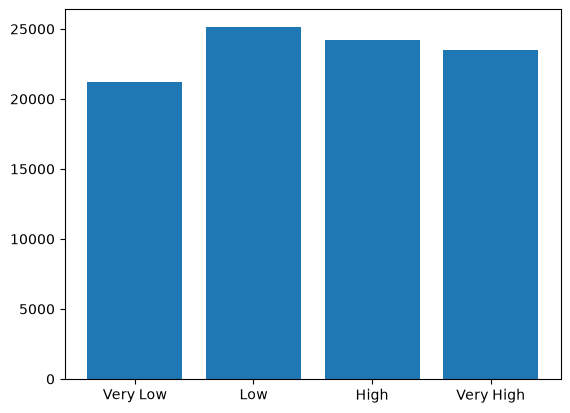

In [17]:
q1_rev= very_low_demand_basmati[very_low_demand_basmati['price_margin_percent']<=very_L_basmati_margin_q1]['revenue'].mean()
q2_rev= very_low_demand_basmati[(very_low_demand_basmati['price_margin_percent']>very_L_basmati_margin_q1)&(very_low_demand_basmati['price_margin_percent']<=very_L_basmati_margin_q2)]['revenue'].mean()
q3_rev= very_low_demand_basmati[(very_low_demand_basmati['price_margin_percent']>very_L_basmati_margin_q2)&(very_low_demand_basmati['price_margin_percent']<=very_L_basmati_margin_q3)]['revenue'].mean()
q4_rev= very_low_demand_basmati[very_low_demand_basmati['price_margin_percent']>very_L_basmati_margin_q3]['revenue'].mean()
plt.bar(x=['Very Low', "Low", "High", 'Very High']
        , height=[q1_rev
                  ,q2_rev
                  ,q3_rev
                  ,q4_rev]
        )

<BarContainer object of 4 artists>

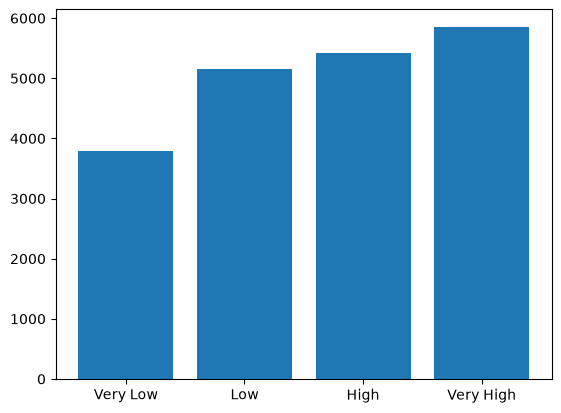

In [52]:
metric_to_use = 'gross_profit'
# metric_to_use = 'gross_profit_margin'
# metric_to_use = 'operating_profit'
q1_rev= very_low_demand_basmati[very_low_demand_basmati['price_margin_percent']<=very_L_basmati_margin_q1][metric_to_use].mean()
q2_rev= very_low_demand_basmati[(very_low_demand_basmati['price_margin_percent']>very_L_basmati_margin_q1)&(very_low_demand_basmati['price_margin_percent']<=very_L_basmati_margin_q2)][metric_to_use].mean()
q3_rev= very_low_demand_basmati[(very_low_demand_basmati['price_margin_percent']>very_L_basmati_margin_q2)&(very_low_demand_basmati['price_margin_percent']<=very_L_basmati_margin_q3)][metric_to_use].mean()
q4_rev= very_low_demand_basmati[very_low_demand_basmati['price_margin_percent']>very_L_basmati_margin_q3][metric_to_use].mean()
plt.bar(x=['Very Low', "Low", "High", 'Very High']
        , height=[q1_rev
                  ,q2_rev
                  ,q3_rev
                  ,q4_rev]
        )

In [29]:
df_oi = high_demand_basmati
df_oi_margin_q1=np.quantile(df_oi['price_margin_percent'], 0.25)
df_oi_margin_q2=np.quantile(df_oi['price_margin_percent'], 0.50)
df_oi_margin_q3=np.quantile(df_oi['price_margin_percent'], 0.75)
df_oi_margin_q1, df_oi_margin_q2, df_oi_margin_q3

(np.float64(1.2345203804690077),
 np.float64(1.2543798455334967),
 np.float64(1.2931001312461987))

<BarContainer object of 4 artists>

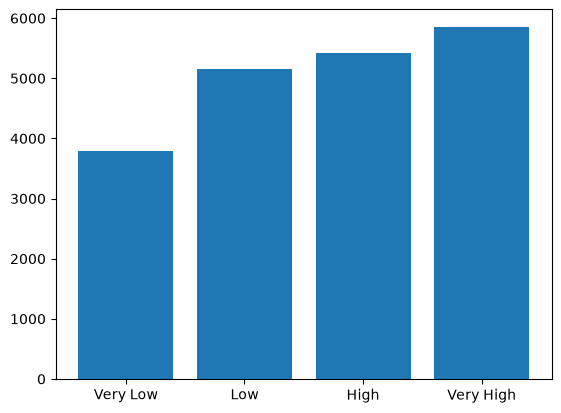

In [55]:
metric_to_use = 'gross_profit'
# metric_to_use = 'gross_profit_margin'
# metric_to_use = 'operating_profit'
q1_rev= df_oi[df_oi['price_margin_percent']<=very_L_basmati_margin_q1][metric_to_use].mean()
q2_rev= df_oi[(df_oi['price_margin_percent']>very_L_basmati_margin_q1)&(df_oi['price_margin_percent']<=very_L_basmati_margin_q2)][metric_to_use].mean()
q3_rev= df_oi[(df_oi['price_margin_percent']>very_L_basmati_margin_q2)&(df_oi['price_margin_percent']<=very_L_basmati_margin_q3)][metric_to_use].mean()
q4_rev= df_oi[df_oi['price_margin_percent']>very_L_basmati_margin_q3][metric_to_use].mean()
plt.bar(x=['Very Low', "Low", "High", 'Very High']
        , height=[q1_rev
                  ,q2_rev
                  ,q3_rev
                  ,q4_rev]
        )

<BarContainer object of 4 artists>

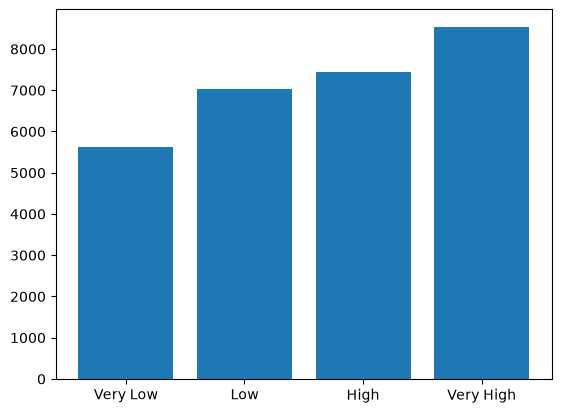

In [56]:
df_oi = r_basmati
df_oi_margin_q1=np.quantile(df_oi['price_margin_percent'], 0.25)
df_oi_margin_q2=np.quantile(df_oi['price_margin_percent'], 0.50)
df_oi_margin_q3=np.quantile(df_oi['price_margin_percent'], 0.75)
df_oi_margin_q1, df_oi_margin_q2, df_oi_margin_q3

metric_to_use = 'gross_profit'
# metric_to_use = 'gross_profit_margin'
# metric_to_use = 'operating_profit'
q1_rev= df_oi[df_oi['price_margin_percent']<=very_L_basmati_margin_q1][metric_to_use].mean()
q2_rev= df_oi[(df_oi['price_margin_percent']>very_L_basmati_margin_q1)&(df_oi['price_margin_percent']<=very_L_basmati_margin_q2)][metric_to_use].mean()
q3_rev= df_oi[(df_oi['price_margin_percent']>very_L_basmati_margin_q2)&(df_oi['price_margin_percent']<=very_L_basmati_margin_q3)][metric_to_use].mean()
q4_rev= df_oi[df_oi['price_margin_percent']>very_L_basmati_margin_q3][metric_to_use].mean()
plt.bar(x=['Very Low', "Low", "High", 'Very High']
        , height=[q1_rev
                  ,q2_rev
                  ,q3_rev
                  ,q4_rev]
        )